# Setup & Load Untouched Raw Data (Kaggle CSV with Semicolon Delimiter)

In [1]:
import glob
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    classification_report, precision_recall_curve
)
from lightgbm import LGBMClassifier
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Anchor working directory to day-11-bank-marketing-propensity/src
PROJECT_SRC = r"C:\Users\adjis\github\100-days-real-world-ml\day-11-bank-marketing-propensity\src"
if os.path.exists(PROJECT_SRC):
    os.chdir(PROJECT_SRC)
os.makedirs("outputs", exist_ok=True)

# Locate bank-additional-full.csv even if extracted inside a subfolder
matches = glob.glob("../data/raw/**/bank-additional-full.csv", recursive=True)
CSV_PATH = matches[0] if matches else "../data/raw/bank-additional-full.csv"

# Note: UCI/Kaggle Bank Marketing CSV uses semicolon ';' delimiter
df_raw = pd.read_csv(CSV_PATH, sep=";")
print(f"Working directory : {os.getcwd()}")
print(f"Raw Dataset Shape : {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()

C:\Users\adjis\anaconda3\envs\100-days-real-world-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Working directory : C:\Users\adjis\github\100-days-real-world-ml\day-11-bank-marketing-propensity\src
Raw Dataset Shape : 41,188 rows, 21 columns


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


# EDA 1: Schema, Duplicates, "unknown" Hidden Missingness & Sentinel 999 Audit

In [2]:
print(f"Standard Nulls       : {df_raw.isnull().sum().sum()}")
print(f"Exact Duplicate Rows : {df_raw.duplicated().sum()}")

audit_records = []
for col in df_raw.columns:
    unknown_cnt = (df_raw[col] == "unknown").sum() if df_raw[col].dtype == "object" else 0
    audit_records.append({
        "Column": col,
        "Dtype": str(df_raw[col].dtype),
        "Unknown_Strings": unknown_cnt,
        "Unknown_Pct (%)": round((unknown_cnt / len(df_raw)) * 100, 2),
        "Unique_Values": df_raw[col].nunique(),
        "Sample_Values": str(df_raw[col].unique()[:3]),
    })
display(pd.DataFrame(audit_records))

# Verify sentinel 999 in pdays and near-zero variance in default
pdays_999_pct = (df_raw["pdays"] == 999).mean() * 100
print(f"\n[SENTINEL ALERT] 'pdays == 999' (Never contacted before): {pdays_999_pct:.2f}% of all rows!")
print("\n'default' value distribution (Extreme sparsity check):")
display(df_raw["default"].value_counts().to_frame("Count"))

Standard Nulls       : 0
Exact Duplicate Rows : 12


,Column,Dtype,Unknown_Strings,Unknown_Pct (%),Unique_Values,Sample_Values
0,age,int64,0,0.0,78,[56 57 37]
1,job,str,0,0.0,12,"<StringArray>\n['housemaid', 'services', 'admi..."
2,marital,str,0,0.0,4,"<StringArray>\n['married', 'single', 'divorced..."
3,education,str,0,0.0,8,"<StringArray>\n['basic.4y', 'high.school', 'ba..."
4,default,str,0,0.0,3,"<StringArray>\n['no', 'unknown', 'yes']\nLengt..."
5,housing,str,0,0.0,3,"<StringArray>\n['no', 'yes', 'unknown']\nLengt..."
6,loan,str,0,0.0,3,"<StringArray>\n['no', 'yes', 'unknown']\nLengt..."
7,contact,str,0,0.0,2,"<StringArray>\n['telephone', 'cellular']\nLeng..."
8,month,str,0,0.0,10,"<StringArray>\n['may', 'jun', 'jul']\nLength: ..."
9,day_of_week,str,0,0.0,5,"<StringArray>\n['mon', 'tue', 'wed']\nLength: ..."



[SENTINEL ALERT] 'pdays == 999' (Never contacted before): 96.32% of all rows!

'default' value distribution (Extreme sparsity check):


,Count
default,
no,32588
unknown,8597
yes,3


# EDA 2: Target Imbalance, duration Leakage Proof & Macroeconomic/Segment Drivers

Target Variable ('y') Distribution:


,Count,Percentage (%)
y,,
no,36548,88.73
yes,4640,11.27



[LEAKAGE PROOF] Call Duration (seconds) vs Subscription Outcome:


,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,36548.0,220.8,207.1,0.0,95.0,163.5,279.0,4918.0
yes,4640.0,553.2,401.2,37.0,253.0,449.0,741.2,4199.0


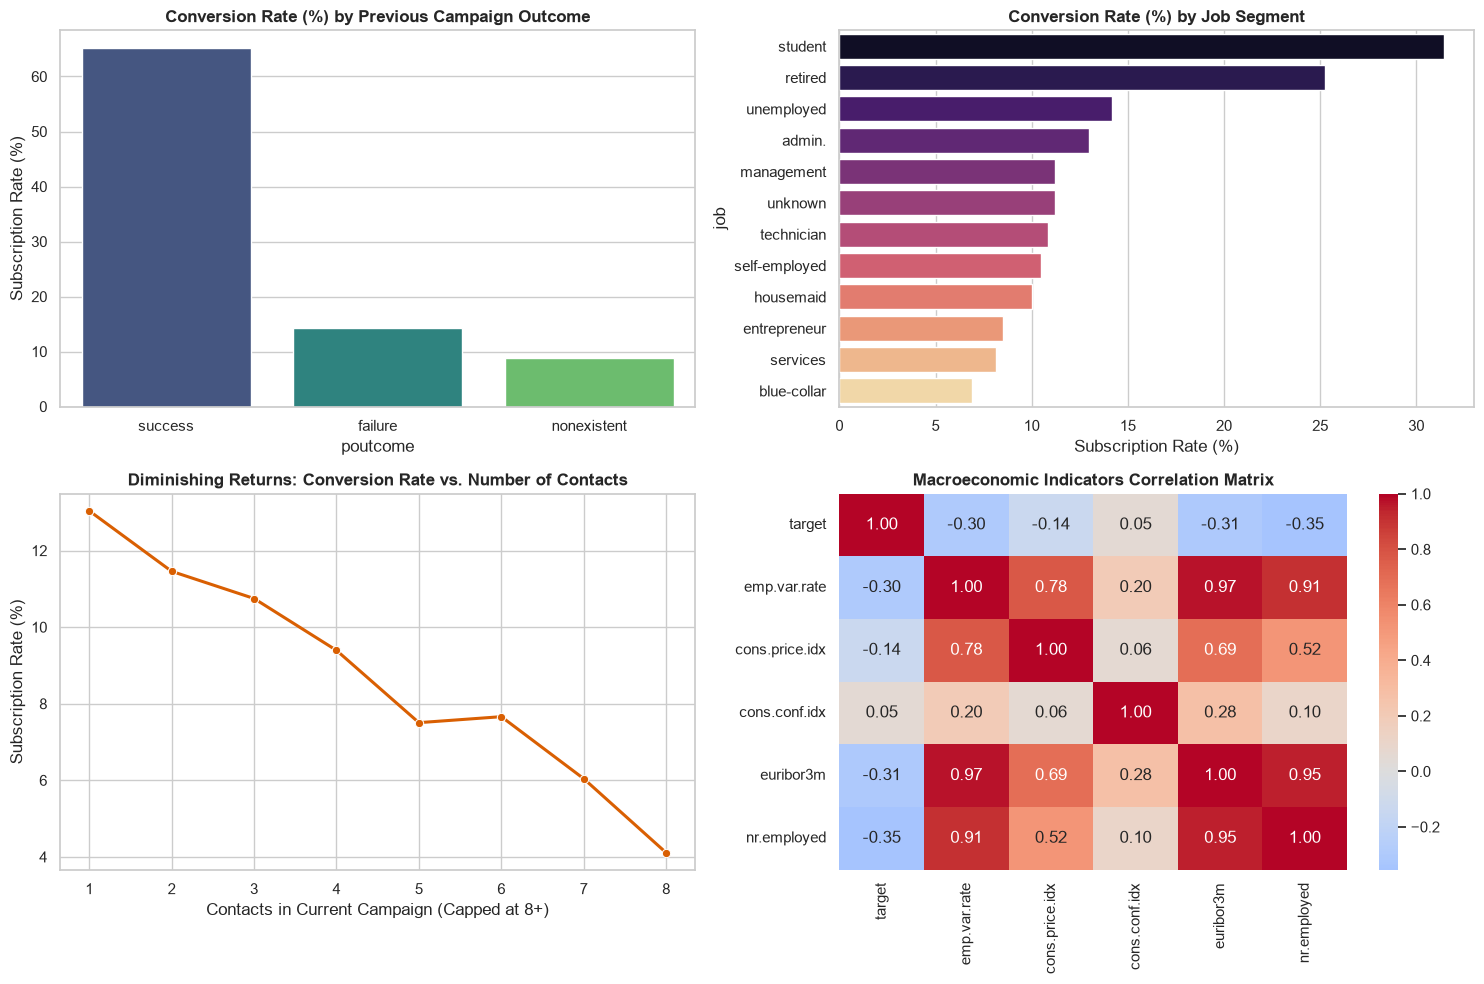

In [3]:
df_eda = df_raw.copy()
df_eda["target"] = (df_eda["y"] == "yes").astype(int)

print("Target Variable ('y') Distribution:")
display(pd.DataFrame({
    "Count": df_raw["y"].value_counts(),
    "Percentage (%)": (df_raw["y"].value_counts(normalize=True) * 100).round(2)
}))

# Prove why 'duration' is post-call leakage
print("\n[LEAKAGE PROOF] Call Duration (seconds) vs Subscription Outcome:")
display(df_eda.groupby("y")["duration"].describe().round(1))

# Visual EDA Dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Subscription Rate by Previous Campaign Outcome ('poutcome')
pout_rate = df_eda.groupby("poutcome")["target"].mean().sort_values(ascending=False) * 100
sns.barplot(x=pout_rate.index, y=pout_rate.values, palette="viridis", ax=axes[0, 0])
axes[0, 0].set_title("Conversion Rate (%) by Previous Campaign Outcome", fontweight="bold")
axes[0, 0].set_ylabel("Subscription Rate (%)")

# Plot 2: Subscription Rate by Job Segment (Highlighting Student & Retired)
job_rate = df_eda.groupby("job")["target"].mean().sort_values(ascending=False) * 100
sns.barplot(x=job_rate.values, y=job_rate.index, palette="magma", ax=axes[0, 1])
axes[0, 1].set_title("Conversion Rate (%) by Job Segment", fontweight="bold")
axes[0, 1].set_xlabel("Subscription Rate (%)")

# Plot 3: Diminishing Returns from Repeated Calling ('campaign')
camp_capped = df_eda["campaign"].clip(upper=8)
camp_rate = df_eda.groupby(camp_capped)["target"].mean() * 100
sns.lineplot(x=camp_rate.index, y=camp_rate.values, marker="o", color="#d95f02", linewidth=2.2, ax=axes[1, 0])
axes[1, 0].set_title("Diminishing Returns: Conversion Rate vs. Number of Contacts", fontweight="bold")
axes[1, 0].set_xlabel("Contacts in Current Campaign (Capped at 8+)")
axes[1, 0].set_ylabel("Subscription Rate (%)")

# Plot 4: Macroeconomic Correlation Matrix (euribor3m, emp.var.rate, nr.employed)
macro_cols = ["target", "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
sns.heatmap(df_eda[macro_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1, 1])
axes[1, 1].set_title("Macroeconomic Indicators Correlation Matrix", fontweight="bold")

plt.tight_layout()
plt.savefig("outputs/eda_bank_marketing.png", dpi=150)
plt.show()

# Evidence-Based Data Cleaning

In [4]:
"""
Cleaning Rules Driven by EDA Findings:
1. Drop 12 exact duplicate rows found in Cell 2.
2. DROP 'duration' strictly! Call duration is only known AFTER the call ends, making it
   severe post-outcome target leakage for any pre-dial propensity model.
3. Drop 'default' (contains only 3 'yes' rows across 41,188 records — near-zero variance).
4. Keep '"unknown"' in job/education/housing/loan as an informative missingness category.
"""
df_clean = df_raw.drop_duplicates().reset_index(drop=True)
df_clean["target"] = (df_clean["y"] == "yes").astype(int)

# Drop target string, post-call leakage ('duration'), and near-constant 'default'
df_clean.drop(columns=["y", "duration", "default"], inplace=True)

print(f"Cleaned Pre-Dial Dataset Shape: {df_clean.shape[0]:,} rows, {df_clean.shape[1]} columns | Conversion Rate: {df_clean['target'].mean():.2%}")

Cleaned Pre-Dial Dataset Shape: 41,176 rows, 19 columns | Conversion Rate: 11.27%


# Domain Feature Engineering & Leak-Free Preprocessing

In [5]:
df_feat = df_clean.copy()

# 1. Separate sentinel '999' in pdays into binary indicator + clean days count
df_feat["was_previously_contacted"] = (df_feat["pdays"] != 999).astype(int)
df_feat["pdays_clean"] = np.where(df_feat["pdays"] == 999, -1, df_feat["pdays"])
df_feat.drop(columns=["pdays"], inplace=True)

# 2. High-propensity demographic & contact-fatigue features from EDA Cell 3
df_feat["is_high_intent_job"] = df_feat["job"].isin(["student", "retired"]).astype(int)
df_feat["is_overcontacted"] = (df_feat["campaign"] >= 4).astype(int)
df_feat["total_historical_contacts"] = df_feat["campaign"] + df_feat["previous"]

# 3. Seasonal peak quarter indicator (Mar, Sep, Oct, Dec)
df_feat["is_peak_season_month"] = df_feat["month"].isin(["mar", "sep", "oct", "dec"]).astype(int)

X = df_feat.drop(columns=["target"])
y = df_feat["target"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

cat_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
num_cols = X_train.select_dtypes(include=["int64", "float64", "int32"]).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

print(f"Train Set: {X_train.shape} | Test Set: {X_test.shape}")

Train Set: (32940, 23) | Test Set: (8236, 23)


# Model Benchmarking (Logistic Regression vs. LightGBM) & Top-20% Call Capture Lift

In [6]:
def find_optimal_f1_threshold(y_true, y_probs):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_probs)
    f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-8)
    best_idx = np.argmax(f1_scores[:-1])
    return float(thresholds[best_idx])

def top_k_capture_rate(y_true, y_probs, top_frac=0.20):
    n_top = int(len(y_true) * top_frac)
    top_indices = np.argsort(y_probs)[::-1][:n_top]
    return float(y_true[top_indices].sum() / y_true.sum()) * 100.0

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression (Pre-Dial Baseline)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000, n_jobs=-1, random_state=42)),
    ]),
    "LightGBM (Pre-Dial Propensity Engine)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LGBMClassifier(
            n_estimators=350,
            learning_rate=0.03,
            num_leaves=31,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=np.sqrt(scale_pos_weight),
            n_jobs=-1,
            random_state=42,
            verbose=-1,
        )),
    ]),
}

best_model, best_pr_auc = None, 0.0

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_probs = pipeline.predict_proba(X_test)[:, 1]
    opt_thresh = find_optimal_f1_threshold(y_test, y_probs)
    y_pred = (y_probs >= opt_thresh).astype(int)

    roc_auc = roc_auc_score(y_test, y_probs)
    pr_auc = average_precision_score(y_test, y_probs)
    capture_20 = top_k_capture_rate(y_test, y_probs, top_frac=0.20)

    print(f"\n---> {name}")
    print(f"PR-AUC : {pr_auc:.4f} | ROC-AUC : {roc_auc:.4f} | Top-20% Call Capture : {capture_20:.2f}% | Threshold : {opt_thresh:.4f}")
    print(classification_report(y_test, y_pred, target_names=["No Deposit (0)", "Subscribed (1)"]))

    if pr_auc > best_pr_auc:
        best_pr_auc = pr_auc
        best_model = pipeline

joblib.dump(best_model, "outputs/best_bank_marketing_model.joblib")


---> Logistic Regression (Pre-Dial Baseline)
PR-AUC : 0.4441 | ROC-AUC : 0.7996 | Top-20% Call Capture : 64.33% | Threshold : 0.6555
                precision    recall  f1-score   support

No Deposit (0)       0.95      0.91      0.93      7308
Subscribed (1)       0.45      0.59      0.51       928

      accuracy                           0.87      8236
     macro avg       0.70      0.75      0.72      8236
  weighted avg       0.89      0.87      0.88      8236


---> LightGBM (Pre-Dial Propensity Engine)
PR-AUC : 0.4768 | ROC-AUC : 0.8092 | Top-20% Call Capture : 66.70% | Threshold : 0.4594
                precision    recall  f1-score   support

No Deposit (0)       0.94      0.93      0.94      7308
Subscribed (1)       0.50      0.56      0.52       928

      accuracy                           0.89      8236
     macro avg       0.72      0.74      0.73      8236
  weighted avg       0.89      0.89      0.89      8236



['outputs/best_bank_marketing_model.joblib']

# Fast SHAP Explainability (Subsampled for Instant Local Execution)

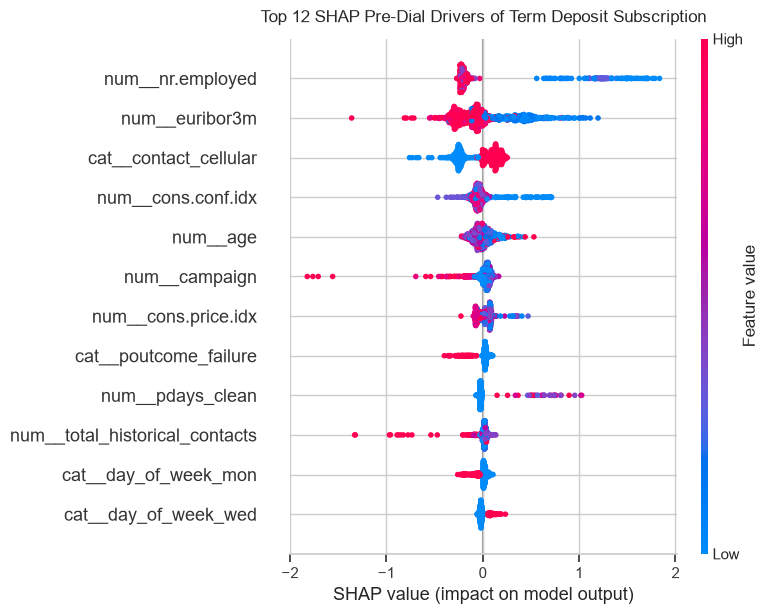

In [7]:
lgbm_pipe = models["LightGBM (Pre-Dial Propensity Engine)"]

X_test_sample = X_test.sample(800, random_state=42)
X_test_transformed = lgbm_pipe.named_steps["preprocessor"].transform(X_test_sample)
feature_names = lgbm_pipe.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(lgbm_pipe.named_steps["classifier"])
shap_values = explainer.shap_values(X_test_transformed)
shap_vals_to_plot = shap_values[1] if isinstance(shap_values, list) else shap_values

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_to_plot, X_test_transformed, feature_names=feature_names, show=False, max_display=12)
plt.title("Top 12 SHAP Pre-Dial Drivers of Term Deposit Subscription", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("outputs/shap_bank_marketing.png", dpi=150)
plt.show()